# Animal re-identification: MiewID vs ConvNeXt Base on WildlifeReID-10k

This follows the project proposal. The two models are trained separately with the same data, the same ArcFace objective and the same tests. The better one is exported for the Flask app and the web page.

**Before you start:** Runtime > Change runtime type > GPU. Then run the cells from top to bottom. Each stage has a short note on what it is for.

**Run time is set by `PROFILE`** in the settings cell:

| profile | data used | epochs per model | use it for |
|---|---|---|---|
| `quick` | 1,500 random identities, up to 8 photos each, 3,000 test queries | 2 + 3 | checking the whole pipeline works and testing the UI |
| `balanced` | all identities, up to 6 photos each, 8,000 test queries | 2 + 4 | results you can report from a normal Colab session |
| `full` | the complete official split | 3 + 8 | the proper run, only realistic on a fast GPU |

Rough guide on a free T4 (estimates, not measurements): `quick` is about 1 to 1.5 hours including the 24 GB download, `balanced` is several hours, `full` is far too long for one free session. The progress bars give real numbers after the first few minutes, so judge from those.

Colab can disconnect during long runs. Checkpoints are saved to Google Drive after every epoch. If it disconnects, reconnect and run all the cells again. Training carries on from the last finished epoch (the dataset download and image cache have to be rebuilt first).

## Stage 0: Setup

Installs the extra libraries, connects Google Drive (checkpoints and results are saved there so they survive a disconnect) and fixes the random seeds so a run can be repeated.

In [ ]:
!pip install -q timm transformers kagglehub scikit-learn

import os, sys, json, time, math, random, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "No GPU found. Runtime > Change runtime type > choose a GPU, then run again."
print("GPU:", torch.cuda.get_device_name(0))

try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/wildlife_reid")
except ImportError:                       # not on Colab
    WORK = Path("./wildlife_reid")
WORK.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Stage 1: Shared model file

Writes `reid_models.py`, which holds the two networks and the image preprocessing. The Flask app imports the same file later, so the model that gets served is built exactly the way it was trained.

MiewID is used as it comes (it already outputs an embedding). For ConvNeXt Base the ImageNet classifier is removed and a Linear + BatchNorm layer is added that gives a 512-d embedding. Training images get light augmentation (small rotation, scale, colour and contrast changes). There are no flips on purpose, because the left and right sides of an animal have different patterns.

In [ ]:
%%writefile reid_models.py
"""Shared by the training notebook and the Flask app.

Both sides import this file, so the network and the image preprocessing used
for serving are exactly the ones used during training.
"""
import torch
import torch.nn as nn
import torchvision.transforms as T

CACHE_SIZE = 440                      # size the training images are cached at
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
BICUBIC = T.InterpolationMode.BICUBIC

SPECS = {
    "miewid":   {"size": 440, "label": "MiewID (EfficientNetV2, wildlife pretrained)"},
    "convnext": {"size": 224, "label": "ConvNeXt Base (ImageNet pretrained)"},
}


def load_miewid():
    """Load conservationxlabs/miewid-msv3 from the Hugging Face hub."""
    from transformers import AutoModel, AutoConfig
    repo = "conservationxlabs/miewid-msv3"
    try:
        return AutoModel.from_pretrained(repo, trust_remote_code=True)
    except Exception:
        # Newer transformers versions expect an attribute the custom MiewID class
        # does not define. Add it to the class and try again.
        from transformers.dynamic_module_utils import get_class_from_dynamic_module
        cfg = AutoConfig.from_pretrained(repo, trust_remote_code=True)
        try:
            cls = get_class_from_dynamic_module(cfg.auto_map["AutoModel"], repo)
        except Exception:
            cls = AutoModel._model_mapping[type(cfg)]
        if not hasattr(cls, "all_tied_weights_keys"):
            cls.all_tied_weights_keys = property(lambda self: {})
        return AutoModel.from_pretrained(repo, trust_remote_code=True)


class EmbeddingNet(nn.Module):
    """backbone -> neck -> embedding vector.

    miewid:   the pretrained MiewID model already outputs the embedding, no extra layer.
    convnext: ImageNet ConvNeXt Base, classifier removed, new Linear + BatchNorm
              layer on top that produces a 512-d embedding.
    """

    def __init__(self, kind, pretrained=True):
        super().__init__()
        self.kind = kind
        if kind == "miewid":
            self.backbone = load_miewid()
            self.neck = nn.Identity()
            size = SPECS[kind]["size"]
            was_training = self.backbone.training
            self.backbone.eval()
            with torch.no_grad():
                self.dim = int(self._out(self.backbone(torch.zeros(1, 3, size, size))).shape[1])
            self.backbone.train(was_training)
        elif kind == "convnext":
            import timm
            self.backbone = timm.create_model("convnext_base.fb_in1k", pretrained=pretrained, num_classes=0)
            self.neck = nn.Sequential(nn.Linear(self.backbone.num_features, 512), nn.BatchNorm1d(512))
            self.dim = 512
        else:
            raise ValueError(f"unknown model kind: {kind}")

    @staticmethod
    def _out(o):
        return o[0] if isinstance(o, (tuple, list)) else o

    def features(self, x):
        return self._out(self.backbone(x))

    def forward(self, x):
        return self.neck(self.features(x))


def eval_transform(kind):
    s = SPECS[kind]["size"]
    return T.Compose([
        T.Resize((CACHE_SIZE, CACHE_SIZE), interpolation=BICUBIC),   # no-op for cached images
        T.Resize((s, s), interpolation=BICUBIC),
        T.ToTensor(),
        T.Normalize(MEAN, STD),
    ])


def train_transform(kind):
    """Conservative augmentation. No flips: left and right sides of an animal
    carry different patterns, so a mirrored image can look like another individual."""
    s = SPECS[kind]["size"]
    return T.Compose([
        T.Resize((CACHE_SIZE, CACHE_SIZE), interpolation=BICUBIC),
        T.Resize((s, s), interpolation=BICUBIC),
        T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
        T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02),
        T.ToTensor(),
        T.Normalize(MEAN, STD),
    ])


Overwriting reid_models.py


In [ ]:
sys.path.insert(0, ".")
from reid_models import EmbeddingNet, SPECS, CACHE_SIZE, eval_transform, train_transform

## Stage 2: Settings

All the knobs are in this cell. You only need to touch it to change `PROFILE`, or to lower `bs` if you get an out-of-memory error.

The training plan follows the proposal. In training stage 1 only the new identity head is trained and the pretrained backbone stays frozen. In training stage 2 the last part of the backbone is unfrozen and trained with a smaller learning rate.

In [ ]:
PROFILE = "quick"          # "quick" | "balanced" | "full"

PROFILES = {
    "quick":    dict(max_identities=1500, max_imgs_per_id=8,    test_queries=3000, epochs=(2, 3), val_queries=1000),
    "balanced": dict(max_identities=None, max_imgs_per_id=6,    test_queries=8000, epochs=(2, 4), val_queries=2000),
    "full":     dict(max_identities=None, max_imgs_per_id=None, test_queries=None, epochs=(3, 8), val_queries=3000),
}
P = PROFILES[PROFILE]

# bs = batch size, lr_head1/lr_head2 = head learning rate in training stage 1/2, lr_backbone = stage 2 only
MODEL_CFG = {
    "miewid":   dict(bs=32, lr_head1=1e-3, lr_head2=3e-4, lr_backbone=3e-5),
    "convnext": dict(bs=64, lr_head1=1e-3, lr_head2=3e-4, lr_backbone=5e-5),
}
UNFREEZE_FRACTION = 0.30     # last 30% of the backbone's tensors get trained in training stage 2
ARC_SCALE, ARC_MARGIN = 30.0, 0.30
VAL_UNKNOWN_FRAC = 0.05      # share of training identities hidden to act as "unseen" animals
HOLDOUT_FRAC = 0.15          # share of every other identity's photos kept as validation queries
LAMBDA = 0.5                 # weight of BAKS in the normalised accuracy
SELECT_BY = "norm_acc"       # metric used to choose the model to deploy
CACHE_DIR = Path("/content/cache")
NUM_WORKERS = min(os.cpu_count() or 2, 8)
print(PROFILE, P)

quick {'max_identities': 1500, 'max_imgs_per_id': 8, 'test_queries': 3000, 'epochs': (2, 3), 'val_queries': 1000}


## Stage 3: Load the dataset

Downloads WildlifeReID-10k (about 24 GB, roughly 6 minutes on Colab) and reads `metadata.csv`. The `split` column already holds the official time-aware / similarity-aware split, so it is used as it is and we never make our own random split. Identities that only appear in `test` are the open-set (unknown) animals.

In [ ]:
import kagglehub
DATA_ROOT = Path(kagglehub.dataset_download("wildlifedatasets/wildlifereid-10k"))
meta = pd.read_csv(DATA_ROOT / "metadata.csv", low_memory=False)
meta["row_id"] = meta.index

print(meta.shape)
print(meta.split.value_counts().to_string())
open_set_ids = set(meta[meta.split == "test"].identity) - set(meta[meta.split == "train"].identity)
print("identities:", meta.identity.nunique(), "| open-set identities (test only):", len(open_set_ids))

Using Colab cache for faster access to the 'wildlifereid-10k' dataset.
(140488, 9)
split
train    109927
test      30561
identities: 10772 | open-set identities (test only): 523


## Stage 4: Choose the subset and build the validation split

Two things happen here.

1. The profile cuts the data down if needed (fewer identities, a cap on photos per identity, fewer test queries). The official train/test labels are kept.
2. A validation set is carved out of the **training** split only, so the test set stays untouched until the very end. About 5% of training identities are set aside completely and treated as unseen animals. For every other identity, about 15% of its photos are held back as validation queries: the newest photos where dates exist, whole clusters of near-duplicates where cluster ids exist, random photos otherwise. That keeps near-identical photos from ending up on both sides of the split.

Validation is used to pick the best epoch and to choose each model's unknown-individual threshold.

In [ ]:
rng = np.random.RandomState(SEED)

# 1. optional identity subset. Sampling from all identities keeps the ~5% open-set share.
if P["max_identities"]:
    keep = rng.choice(meta.identity.unique(), P["max_identities"], replace=False)
    meta = meta[meta.identity.isin(keep)]

train_all = meta[meta.split == "train"]
test_all = meta[meta.split == "test"]
known_ids = set(train_all.identity)                 # the identities the system knows

if P["max_imgs_per_id"]:
    train_all = train_all.sample(frac=1, random_state=SEED).groupby("identity").head(P["max_imgs_per_id"])
if P["test_queries"] and len(test_all) > P["test_queries"]:
    test_all = test_all.sample(P["test_queries"], random_state=SEED)

# 2. validation split, taken from the training data only
ids = np.array(sorted(train_all.identity.unique()))
val_unk_ids = set(rng.choice(ids, max(1, int(VAL_UNKNOWN_FRAC * len(ids))), replace=False))
val_unknown = train_all[train_all.identity.isin(val_unk_ids)]
rest = train_all[~train_all.identity.isin(val_unk_ids)].copy()
rest["_date"] = pd.to_datetime(rest["date"], errors="coerce")

def pick_holdout(g):
    n = len(g)
    if n < 2:
        return []
    k = min(max(1, round(HOLDOUT_FRAC * n)), n - 1)               # always leave at least one for training
    if g["_date"].notna().all() and g["_date"].nunique() > 1:     # time aware: newest photos
        return g.sort_values("_date").index[-k:].tolist()
    if g["cluster_id"].notna().all():                             # similarity aware: whole clusters
        clusters = g["cluster_id"].unique()
        if len(clusters) < 2:                                     # every photo is a near-duplicate of the others,
            return []                                             # so there is no clean validation query
        out = []
        for c in rng.permutation(clusters)[:-1]:                  # the last cluster always stays in training
            out += g.index[g["cluster_id"] == c].tolist()
            if len(out) >= k:
                break
        return out
    return g.index[rng.permutation(n)[:k]].tolist()               # nothing else available: random

hold = [i for _, g in rest.groupby("identity") for i in pick_holdout(g)]
val_known = rest.loc[hold]
train_df = rest.drop(index=hold)

test_df = test_all.copy()
test_df["is_known"] = test_df.identity.isin(known_ids)

summary = pd.DataFrame({
    "images": [len(train_df), len(val_known), len(val_unknown), len(test_df)],
    "identities": [train_df.identity.nunique(), val_known.identity.nunique(), val_unknown.identity.nunique(), test_df.identity.nunique()],
}, index=["train", "validation (known)", "validation (unknown)", "test"])
print(summary)
print("test queries: known =", int(test_df.is_known.sum()), "| unknown =", int((~test_df.is_known).sum()))

                      images  identities
train                   5180        1360
validation (known)      1192        1080
validation (unknown)     296          71
test                    3000         980
test queries: known = 2122 | unknown = 878


## Stage 5: Cache resized copies of the images

The original photos are big, and decoding them again every epoch would leave the GPU waiting for the CPU. Every image used in this run is resized once to 440x440 and saved as a small JPEG on the local disk. Both models read from this cache (ConvNeXt shrinks the images to 224 when it loads them). Images that fail to open are dropped here.

This is a one-off cost for the run, and it is the slowest part of the setup on the 2-core free Colab CPU.

In [ ]:
from multiprocessing import Pool
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def _cache_one(job):
    src, dst = job
    if os.path.exists(dst):
        return True
    try:
        im = Image.open(src)
        im.draft("RGB", (CACHE_SIZE, CACHE_SIZE))          # lets the JPEG decoder skip work on huge photos
        im.convert("RGB").resize((CACHE_SIZE, CACHE_SIZE), Image.BICUBIC).save(dst, quality=92)
        return True
    except Exception:
        return False

need = pd.concat([train_df, val_known, val_unknown, test_df])
jobs = [(str(DATA_ROOT / p), str(CACHE_DIR / f"{r}.jpg")) for p, r in zip(need.path, need.row_id)]
with Pool(min(8, (os.cpu_count() or 2) * 2)) as pool:
    ok = list(tqdm(pool.imap(_cache_one, jobs, chunksize=64), total=len(jobs), desc="caching"))

bad = set(need.row_id.values[~np.array(ok)])
print("images that could not be read:", len(bad))
train_df, val_known, val_unknown, test_df = [d[~d.row_id.isin(bad)] for d in (train_df, val_known, val_unknown, test_df)]

caching:   0%|          | 0/9668 [00:00<?, ?it/s]

images that could not be read: 0


## Stage 6: Labels, data loaders and embedding extraction

Builds the lookup tables that turn identity names into numbers, and the dataset class that reads from the cache. It also defines `embed`, which turns any set of images into normalised embedding vectors. Augmentation is only used by the training loader. Everything that is evaluated uses plain resizing.

The final gallery is every labelled photo from the training split (training photos plus the validation photos). The validation identities that were hidden during training are in the gallery too, because they are known animals in the real catalogue.

In [ ]:
code = {n: i for i, n in enumerate(sorted(set(meta.identity)))}      # every identity name -> integer
train_classes = sorted(train_df.identity.unique())
cls_of = {n: i for i, n in enumerate(train_classes)}                # training identities -> 0..C-1 (ArcFace classes)
N_CLASSES = len(train_classes)
train_labels = train_df.identity.map(cls_of).values
gallery_df = pd.concat([train_df, val_known, val_unknown])           # order matters: embeddings are stored in this order
print("ArcFace classes:", N_CLASSES, "| gallery photos:", len(gallery_df))

class ImgDS(Dataset):
    def __init__(self, df, tfm, labels=None):
        self.p = [str(CACHE_DIR / f"{r}.jpg") for r in df.row_id]
        self.tfm, self.y = tfm, (None if labels is None else np.asarray(labels))
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        x = self.tfm(Image.open(self.p[i]).convert("RGB"))
        return x if self.y is None else (x, int(self.y[i]))

@torch.no_grad()
def embed(net, df, kind):
    net.eval()
    dl = DataLoader(ImgDS(df, eval_transform(kind)), batch_size=MODEL_CFG[kind]["bs"] * 2, shuffle=False,
                    num_workers=NUM_WORKERS, pin_memory=True)
    out = []
    for x in tqdm(dl, leave=False, desc="embedding"):
        with torch.autocast("cuda", dtype=torch.float16):
            f = net(x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last))
        out.append(F.normalize(f.float(), dim=1).cpu())
    return torch.cat(out)

ArcFace classes: 1360 | gallery photos: 6668


## Stage 7: Similarity search and metrics

Everything used to judge a model is here.

- `search` compares query embeddings with the gallery using cosine similarity (the vectors are already normalised, so it is a dot product). It returns each query's best matches and its average precision.
- `closed_metrics` gives Top-1, Top-5 and mAP for queries whose identity is in the gallery.
- `open_metrics` gives BAKS (known photos that were identified correctly and accepted, averaged per individual), BAUS (unknown photos that were correctly rejected, averaged per individual) and the normalised accuracy that combines them as a weighted average with `LAMBDA`. If your report defines normalised accuracy differently, change it in this one function.
- `pick_threshold` tries many values of the threshold tau and keeps the one with the best normalised accuracy. It is only ever run on validation data.

In [ ]:
@torch.no_grad()
def search(Q, G, g_lab, q_true, k=100, ap=True, chunk=128):
    Gd = G.to(device)
    gl = torch.as_tensor(np.asarray(g_lab), device=device)
    qt = torch.as_tensor(np.asarray(q_true), device=device)
    N = Gd.shape[0]
    ranks = torch.arange(1, N + 1, device=device, dtype=torch.float32)
    sims, labs, aps = [], [], []
    for i in range(0, len(Q), chunk):
        s = Q[i:i + chunk].to(device) @ Gd.T
        ts, ti = s.topk(min(k, N), dim=1)
        sims.append(ts.cpu()); labs.append(gl[ti].cpu())
        if ap:                                           # average precision over the whole ranked gallery
            hit = (gl[s.argsort(dim=1, descending=True)] == qt[i:i + chunk, None]).float()
            prec = hit.cumsum(1) / ranks
            aps.append(((prec * hit).sum(1) / hit.sum(1).clamp(min=1)).cpu())
    del Gd
    return torch.cat(sims).numpy(), torch.cat(labs).numpy(), (torch.cat(aps).numpy() if ap else None)

def closed_metrics(top_labs, aps, q_true):
    kn = q_true >= 0                                     # q_true is -1 for unknown queries
    top1 = float((top_labs[kn, 0] == q_true[kn]).mean())
    top5 = float(np.mean([q in list(dict.fromkeys(row))[:5] for row, q in zip(top_labs[kn], q_true[kn])]))
    return top1, top5, float(aps[kn].mean())

def open_metrics(top_sim, top_lab, q_true, q_group, tau):
    kn = q_true >= 0
    right_and_accepted = (top_lab == q_true) & (top_sim >= tau)
    baks = pd.Series(right_and_accepted[kn]).groupby(q_group[kn]).mean().mean()
    baus = pd.Series(top_sim[~kn] < tau).groupby(q_group[~kn]).mean().mean() if (~kn).any() else float("nan")
    return float(baks), float(baus), float(LAMBDA * baks + (1 - LAMBDA) * baus)

def pick_threshold(top_sim, top_lab, q_true, q_group):
    grid = np.linspace(0, 1, 201)
    scores = np.array([open_metrics(top_sim, top_lab, q_true, q_group, t)[2] for t in grid])
    return 0.5 if np.isnan(scores).all() else float(grid[int(np.nanargmax(scores))])

## Stage 8: Training code

Defines ArcFace and the training loop. Nothing runs in this cell.

- **ArcFace** adds an angular margin to the correct identity. That forces embeddings of the same animal into a tight group and pushes different animals apart. It only exists during training and is thrown away afterwards, so only the embedding network is deployed.
- **Training stage 1** keeps the backbone frozen and trains the new head only. The head can settle without damaging the pretrained features.
- **Training stage 2** unfreezes the last `UNFREEZE_FRACTION` of the backbone and trains it with a small learning rate, so the features adapt to WildlifeReID-10k.
- Learning rates warm up for a few steps and then decay on a cosine curve. Mixed precision is used to save time and memory.
- After every epoch a quick validation runs and the best epoch is kept (the final model is the best epoch, not the last one). The quick validation uses a small gallery of 2 photos per identity so it stays cheap.
- `finalize` runs once at the end and does the proper evaluation.

In [ ]:
class ArcFace(nn.Module):
    def __init__(self, dim, n_classes, s=30.0, m=0.30):
        super().__init__()
        self.W = nn.Parameter(torch.empty(n_classes, dim)); nn.init.xavier_uniform_(self.W)
        self.s, self.cos_m, self.sin_m = s, math.cos(m), math.sin(m)
        self.th, self.mm = math.cos(math.pi - m), math.sin(math.pi - m) * m
    def forward(self, emb, y):
        with torch.autocast("cuda", enabled=False):
            cos = F.linear(F.normalize(emb.float()), F.normalize(self.W)).clamp(-1 + 1e-7, 1 - 1e-7)
            phi = cos * self.cos_m - (1 - cos ** 2).sqrt() * self.sin_m          # cos(theta + m)
            phi = torch.where(cos > self.th, phi, cos - self.mm)
            onehot = F.one_hot(y, cos.shape[1]).bool()
            return F.cross_entropy(self.s * torch.where(onehot, phi, cos), y)

def set_stage(net, stage):
    """stage 1: backbone frozen. stage 2: last UNFREEZE_FRACTION of the backbone trainable."""
    params = list(net.backbone.parameters())
    for p in params:
        p.requires_grad = False
    if stage == 2:
        for p in params[int(len(params) * (1 - UNFREEZE_FRACTION)):]:
            p.requires_grad = True
    return [p for p in params if p.requires_grad]

def make_sched(opt, total, warm=0.05):
    def f(step):
        if step < warm * total:
            return (step + 1) / (warm * total)
        prog = (step - warm * total) / max(1, total - warm * total)
        return 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

# small validation set used after every epoch (to keep the best epoch)
vg_df = train_df.groupby("identity").head(2)
vq_known = val_known.sample(min(P["val_queries"], len(val_known)), random_state=SEED)
vq_unk = val_unknown.sample(min(max(1, P["val_queries"] // 2), len(val_unknown)), random_state=SEED)

def quick_val(net, kind):
    Gv, Qk, Qu = embed(net, vg_df, kind), embed(net, vq_known, kind), embed(net, vq_unk, kind)
    g_lab = vg_df.identity.map(code).values
    k_lab, u_lab = vq_known.identity.map(code).values, vq_unk.identity.map(code).values
    q_true = np.r_[k_lab, -np.ones(len(u_lab), dtype=int)]
    q_group = np.r_[k_lab, u_lab]
    s, l, ap = search(torch.cat([Qk, Qu]), Gv, g_lab, q_true, k=20)
    top1, top5, mAP = closed_metrics(l, ap, q_true)
    tau = pick_threshold(s[:, 0], l[:, 0], q_true, q_group)
    return dict(top1=round(top1, 4), mAP=round(mAP, 4), norm_acc=round(open_metrics(s[:, 0], l[:, 0], q_true, q_group, tau)[2], 4), tau=tau)

def train_model(key):
    mc = MODEL_CFG[key]
    out = WORK / key; out.mkdir(exist_ok=True)
    torch.cuda.reset_peak_memory_stats()
    net = EmbeddingNet(key).to(device).to(memory_format=torch.channels_last)
    assert not any(p.is_meta for p in net.parameters()), "model weights were not loaded"
    print(f"{SPECS[key]['label']}: embedding size {net.dim}, {sum(p.numel() for p in net.parameters()) / 1e6:.1f}M parameters")
    arc = ArcFace(net.dim, N_CLASSES, ARC_SCALE, ARC_MARGIN).to(device)
    loader = DataLoader(ImgDS(train_df, train_transform(key), train_labels), batch_size=mc["bs"], shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True, persistent_workers=True)
    E1, E2 = P["epochs"]; total = E1 + E2
    done, best, history, minutes = 0, -1.0, [], 0.0
    if (out / "last.pt").exists():
        ck = torch.load(out / "last.pt", map_location=device, weights_only=False)
        net.load_state_dict(ck["net"]); arc.load_state_dict(ck["arc"])
        done, best, history, minutes = ck["done"], ck["best"], ck["history"], ck["minutes"]
        print(f"resuming after epoch {done} of {total}")
    elif key == "miewid":
        print("before any training (zero-shot):", quick_val(net, key))

    scaler = torch.amp.GradScaler("cuda")
    cur_stage = opt = sched = None
    for ep in range(done, total):
        stage = 1 if ep < E1 else 2
        if stage != cur_stage:                                   # new stage: new optimiser and schedule
            cur_stage = stage
            backbone_params = set_stage(net, stage)
            groups = [dict(params=list(net.neck.parameters()) + list(arc.parameters()),
                           lr=mc["lr_head1"] if stage == 1 else mc["lr_head2"])]
            if stage == 2:
                groups.append(dict(params=backbone_params, lr=mc["lr_backbone"]))
            opt = torch.optim.AdamW(groups, weight_decay=1e-4)
            sched = make_sched(opt, (E1 if stage == 1 else E2) * len(loader))
            for _ in range((ep - (0 if stage == 1 else E1)) * len(loader)):   # catch up when resuming mid-stage
                sched.step()

        net.train()
        if stage == 1:
            net.backbone.eval()                                  # frozen backbone also keeps its BatchNorm statistics
        t0, run = time.time(), torch.zeros((), device=device)
        pbar = tqdm(loader, desc=f"{key} epoch {ep + 1}/{total} (stage {stage})", leave=False)
        for i, (x, y) in enumerate(pbar):
            x = x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16):
                with torch.set_grad_enabled(stage == 2):         # no gradients through a frozen backbone
                    f = net.features(x)
                emb = net.neck(f)
            loss = arc(emb, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.detach()
            if i % 25 == 0:
                pbar.set_postfix(loss=f"{loss.item():.3f}")
        minutes += (time.time() - t0) / 60

        v = quick_val(net, key)
        history.append(dict(epoch=ep + 1, stage=stage, loss=round(float(run) / len(loader), 4), **v))
        print(f"epoch {ep + 1}/{total} stage {stage} | loss {history[-1]['loss']} | val top1 {v['top1']} "
              f"| val norm_acc {v['norm_acc']} | {(time.time() - t0) / 60:.1f} min")
        if v["norm_acc"] > best:
            best = v["norm_acc"]; torch.save(net.state_dict(), out / "best.pt")
        torch.save(dict(net=net.state_dict(), arc=arc.state_dict(), done=ep + 1, best=best,
                        history=history, minutes=minutes), out / "last.pt")

    del loader
    net.load_state_dict(torch.load(out / "best.pt", map_location=device))
    return net, minutes

def finalize(key, net, minutes):
    mc = MODEL_CFG[key]; out = WORK / key
    # 1. embeddings of the gallery pieces
    Gt, Vk, Vu = embed(net, train_df, key), embed(net, val_known, key), embed(net, val_unknown, key)
    g_lab = train_df.identity.map(code).values
    vk_lab, vu_lab = val_known.identity.map(code).values, val_unknown.identity.map(code).values
    # 2. threshold from validation data only: validation queries against the training photos
    q_true = np.r_[vk_lab, -np.ones(len(vu_lab), dtype=int)]
    s, l, _ = search(torch.cat([Vk, Vu]), Gt, g_lab, q_true, k=1, ap=False)
    tau = pick_threshold(s[:, 0], l[:, 0], q_true, np.r_[vk_lab, vu_lab])
    # 3. test set, scored once. Gallery = all labelled photos from the train split.
    G, G_lab = torch.cat([Gt, Vk, Vu]), np.r_[g_lab, vk_lab, vu_lab]
    Te = embed(net, test_df, key)
    t_code = test_df.identity.map(code).values
    t_true = np.where(test_df.is_known.values, t_code, -1)
    s, l, ap = search(Te, G, G_lab, t_true, k=100, ap=True)
    top1, top5, mAP = closed_metrics(l, ap, t_true)
    baks, baus, na = open_metrics(s[:, 0], l[:, 0], t_true, t_code, tau)
    auroc = float(roc_auc_score((t_true >= 0).astype(int), s[:, 0]))
    # 4. speed and memory
    x = torch.randn(1, 3, SPECS[key]["size"], SPECS[key]["size"], device=device).contiguous(memory_format=torch.channels_last)
    net.eval()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for _ in range(5): net(x)
        torch.cuda.synchronize(); t0 = time.time()
        for _ in range(30): net(x)
        torch.cuda.synchronize()
    res = dict(model=key, profile=PROFILE, top1=top1, top5=top5, mAP=mAP, baks=baks, baus=baus, norm_acc=na, auroc=auroc,
               tau=tau, infer_ms=(time.time() - t0) / 30 * 1000, params_m=sum(p.numel() for p in net.parameters()) / 1e6,
               peak_gb=torch.cuda.max_memory_allocated() / 2 ** 30, train_minutes=minutes,
               gallery_photos=len(G), test_known=int((t_true >= 0).sum()), test_unknown=int((t_true < 0).sum()))
    np.save(out / "gallery_emb.npy", G.half().numpy())
    gallery_df[["identity", "species", "dataset", "path", "row_id"]].to_csv(out / "gallery_df.csv", index=False)
    np.savez(out / "test_scores.npz", score=s[:, 0], known=(t_true >= 0))
    json.dump(res, open(out / "results.json", "w"), indent=2)
    return res

def run_model(key):
    if (WORK / key / "results.json").exists():
        print(key, "already finished, loading saved results")
        return json.load(open(WORK / key / "results.json"))
    net, minutes = train_model(key)
    res = finalize(key, net, minutes)
    del net; torch.cuda.empty_cache()
    return res

## Stage 9: Train and evaluate MiewID

Before any training it prints a zero-shot score: how well the pretrained MiewID already does on validation data. This doubles as a check that the weights loaded properly. If Top-1 comes out close to 0, the model did not load correctly, so stop and look at that before waiting hours.

When training finishes, `finalize` builds the full gallery, picks the threshold from validation data only, scores the test set once, and measures inference time and memory.

In [ ]:
res_miewid = run_model("miewid")
res_miewid

miewid already finished, loading saved results


{'model': 'miewid',
 'profile': 'quick',
 'top1': 0.7719132893496701,
 'top5': 0.8732327992459944,
 'mAP': 0.6157878041267395,
 'baks': 0.43670581931095503,
 'baus': 0.9949974012474012,
 'norm_acc': 0.7158516102791781,
 'auroc': 0.8727373926261166,
 'tau': 0.555,
 'infer_ms': 37.20919291178385,
 'params_m': 51.109277,
 'peak_gb': 3.7121520042419434,
 'train_minutes': 11.430582988262177,
 'gallery_photos': 6668,
 'test_known': 2122,
 'test_unknown': 878}

## Stage 10: Train and evaluate ConvNeXt Base

Same pipeline and the same settings with a different backbone. The "before training" score is skipped here because its embedding layer is brand new, so the number would mean nothing.

In [ ]:
res_convnext = run_model("convnext")
res_convnext

ConvNeXt Base (ImageNet pretrained): embedding size 512, 88.1M parameters


convnext epoch 1/5 (stage 1):   0%|          | 0/80 [00:00<?, ?it/s]

embedding:   0%|          | 0/18 [00:00<?, ?it/s]

embedding:   0%|          | 0/8 [00:00<?, ?it/s]

embedding:   0%|          | 0/3 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x792d4fa8d580>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x792d4fa8d580>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

embedding:   0%|          | 0/3 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x792d4fa8d580>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x792d4fa8d580>    
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        self._shutdown_workers()if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
AssertionErrorif w.is_alive():: Exception ignored in: 
  File "/usr/lib/python3.

embedding:   0%|          | 0/24 [00:00<?, ?it/s]

{'model': 'convnext',
 'profile': 'quick',
 'top1': 0.5094250706880301,
 'top5': 0.6894439208294062,
 'mAP': 0.3908829987049103,
 'baks': 0.048820157280855966,
 'baus': 0.9709136558370062,
 'norm_acc': 0.5098669065589311,
 'auroc': 0.5985134580992273,
 'tau': 0.96,
 'infer_ms': 16.251754760742188,
 'params_m': 88.092288,
 'peak_gb': 2.6245312690734863,
 'train_minutes': 6.244644578297933,
 'gallery_photos': 6668,
 'test_known': 2122,
 'test_unknown': 878}

## Stage 11: Compare the models

Puts both result sets side by side and picks the model to deploy using `SELECT_BY` (normalised accuracy by default, because the app has to cope with unknown animals). The histograms show how well each model separates photos of known animals from photos of unknown ones. The threshold sits where the two groups overlap the least.

MiewID's original training data partly overlaps with WildlifeReID-10k (the benchmark authors say so too). Keep that caveat next to its numbers in the report.

,top1,top5,mAP,baks,baus,norm_acc,auroc,tau,infer_ms,params_m,peak_gb,train_minutes
miewid,0.772,0.873,0.616,0.437,0.995,0.716,0.873,0.555,37.209,51.109,3.712,11.431
convnext,0.509,0.689,0.391,0.049,0.971,0.510,0.599,0.960,16.252,88.092,2.625,6.245


Deploying: miewid (best norm_acc = 0.716)


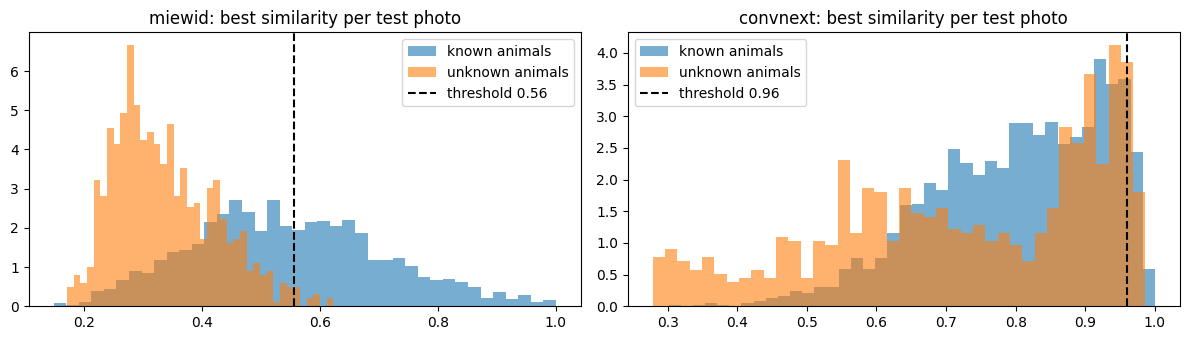

In [ ]:
import matplotlib.pyplot as plt
res = {k: json.load(open(WORK / k / "results.json")) for k in ["miewid", "convnext"] if (WORK / k / "results.json").exists()}
cols = ["top1", "top5", "mAP", "baks", "baus", "norm_acc", "auroc", "tau", "infer_ms", "params_m", "peak_gb", "train_minutes"]
table = pd.DataFrame(res).T[cols].astype(float)
display(table.style.format("{:.3f}"))

winner = table[SELECT_BY].idxmax()
print(f"Deploying: {winner} (best {SELECT_BY} = {table.loc[winner, SELECT_BY]:.3f})")

fig, axes = plt.subplots(1, len(res), figsize=(6 * len(res), 3.5), squeeze=False)
for ax, k in zip(axes[0], res):
    z = np.load(WORK / k / "test_scores.npz")
    ax.hist(z["score"][z["known"]], bins=40, alpha=.6, density=True, label="known animals")
    ax.hist(z["score"][~z["known"]], bins=40, alpha=.6, density=True, label="unknown animals")
    ax.axvline(res[k]["tau"], color="k", ls="--", label=f"threshold {res[k]['tau']:.2f}")
    ax.set_title(f"{k}: best similarity per test photo"); ax.legend()
plt.tight_layout(); plt.show()

## Stage 12: Export for the Flask app

Packages what the app needs: the winning model's weights, the gallery embeddings, the threshold, and one small reference photo per individual so the web page can show what a match looks like. The zip is written to Google Drive (and a download is attempted). On your machine, unzip it into `reid_app/model_files/`.

In [ ]:
from multiprocessing import Pool
src = WORK / winner
EXPORT = Path("/content/reid_export")
shutil.rmtree(EXPORT, ignore_errors=True); (EXPORT / "thumbs").mkdir(parents=True)

shutil.copy(src / "best.pt", EXPORT / "weights.pt")
shutil.copy(src / "gallery_emb.npy", EXPORT / "gallery_emb.npy")
gdf = pd.read_csv(src / "gallery_df.csv")                      # same row order as the embeddings
gdf[["identity"]].to_csv(EXPORT / "gallery_meta.csv", index=False)

reps = gdf.drop_duplicates("identity").reset_index(drop=True)  # one reference photo per individual
reps["thumb"] = [f"t{i:05d}.jpg" for i in range(len(reps))]

def _thumb(job):
    s, d = job
    try:
        im = Image.open(s); im.draft("RGB", (512, 512))
        im = im.convert("RGB"); im.thumbnail((256, 256)); im.save(d, quality=85)
        return True
    except Exception:
        return False

jobs = [(str(DATA_ROOT / p), str(EXPORT / "thumbs" / t)) for p, t in zip(reps.path, reps.thumb)]
with Pool(min(8, (os.cpu_count() or 2) * 2)) as pool:
    ok = list(tqdm(pool.imap(_thumb, jobs, chunksize=32), total=len(jobs), desc="thumbnails"))
reps.loc[~np.array(ok), "thumb"] = np.nan
reps[["identity", "species", "dataset", "thumb"]].to_csv(EXPORT / "identities.csv", index=False)

r = res[winner]
json.dump(dict(kind=winner, label=SPECS[winner]["label"], size=SPECS[winner]["size"], threshold=r["tau"], profile=PROFILE,
               embedding_dim=int(np.load(EXPORT / "gallery_emb.npy", mmap_mode="r").shape[1]),
               metrics={m: round(r[m], 4) for m in ["top1", "top5", "mAP", "baks", "baus", "norm_acc", "auroc"]}),
          open(EXPORT / "config.json", "w"), indent=2)

zip_path = shutil.make_archive(str(WORK / "reid_export"), "zip", EXPORT)
print("Export written to:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Automatic download not available. Take the zip from Google Drive: wildlife_reid/reid_export.zip")

thumbnails:   0%|          | 0/1431 [00:00<?, ?it/s]

Export written to: /content/drive/MyDrive/wildlife_reid/reid_export.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next, in VS Code

1. Unzip `reid_export.zip` into `reid_app/model_files/` (so `reid_app/model_files/weights.pt` exists).
2. `pip install -r requirements.txt`
3. `python app.py`, then open http://127.0.0.1:5000 and upload an animal photo.

The first start needs internet if MiewID won. Its code is fetched from the Hugging Face hub once and cached after that.